# CO₂ methanation: preprocessing and visualization

In [53]:
from pathlib import Path

import camelot
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
PDF_PATH = ROOT / 'data' / 'data.pdf'
OUTPUT_CSV = ROOT / 'data' / 'processed' / 'co2_methanation_clean.csv'
FIGURE_DIR = ROOT / 'reports' / 'figures'
OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

## 1. Extract the supplementary table

Camelot extracts the five page sections of Table S1. Converting every field to numeric automatically identifies the table titles, units, and repeated page headers; only those non-data rows are removed.

In [54]:
columns = [
    'test_id', 'temperature_C', 'CO2_pct', 'H2_pct', 'Ar_pct',
    'GHSV_h-1', 'flowrate_NmL_min', 'CH4_yield_pct'
]

tables = camelot.read_pdf(str(PDF_PATH), pages='4-8', flavor='stream')
if len(tables) != 5:
    raise ValueError(f'Expected 5 table sections, found {len(tables)}')

raw = pd.concat([table.df for table in tables], ignore_index=True)
raw.columns = columns
df = raw.apply(pd.to_numeric, errors='coerce').dropna(how='any').drop_duplicates(subset=raw.columns.drop('test_id')).reset_index(drop=True)
print(f'Extracted {len(df)} experimental rows')
df.head()

Extracted 215 experimental rows


,test_id,temperature_C,CO2_pct,H2_pct,Ar_pct,GHSV_h-1,flowrate_NmL_min,CH4_yield_pct
0,1.0,240.0,20.0,80.0,0.0,144000.0,599.0,11.09
1,2.0,251.0,20.0,80.0,0.0,144000.0,599.0,17.27
2,3.0,261.0,19.9,80.1,0.0,144000.0,599.0,25.56
3,4.0,272.0,20.0,80.0,0.0,144000.0,599.0,34.50
4,5.0,280.0,20.0,80.0,0.0,144000.0,599.0,43.86


## 2. Validate and create model-ready features

In [55]:
# physical-quality checks

assert df.isna().sum().sum() == 0, 'Missing experimental values found'
assert df['test_id'].is_unique, 'test_id must be unique'
assert df.drop(columns='test_id').duplicated().sum() == 0, 'Duplicate values found' 
assert df[['CO2_pct', 'H2_pct', 'Ar_pct', 'CH4_yield_pct']].apply(lambda column: column.between(0, 100).all()).all(), 'A percentage lies outside 0–100%'

gas_sum = df[['CO2_pct', 'H2_pct', 'Ar_pct']].sum(axis=1)
assert gas_sum.between(99.8, 100.2).all(), 'Gas percentages do not sum to about 100%'
assert (df[['temperature_C', 'GHSV_h-1', 'flowrate_NmL_min']] > 0).all().all()


The total pressure was fixed at 3 bar, so component partial pressures can also be calculated directly.

In [56]:

# feature engineering
df['test_id'] = df['test_id'].astype(int)
df['H2_CO2_ratio'] = df['H2_pct'] / df['CO2_pct']
for gas in ['CO2', 'H2', 'Ar']:
    fraction = df[f'{gas}_pct'] / 100
    df[f'{gas}_flow_NmL_min'] = df['flowrate_NmL_min'] * fraction
    df[f'{gas}_partial_pressure_bar'] = 3.0 * fraction
df['pressure_bar'] = 3.0

df.to_csv(OUTPUT_CSV, index=False, float_format='%.6f')
print(f'Saved final dataset: {OUTPUT_CSV}')
print(f'Final shape: {df.shape[0]} rows  {df.shape[1]} columns')

Saved final dataset: /home/oafidi/Documents/ai/co2-methanation-ml/data/processed/co2_methanation_clean.csv
Final shape: 215 rows  16 columns


In [57]:
quality_summary = pd.Series({
    'rows': len(df),
    'columns': len(df.columns),
    'missing_values': int(df.isna().sum().sum()),
    'unique_test_ids': int(df['test_id'].nunique()),
    'exact_experimental_replicates': int(df.drop(columns='test_id').duplicated().sum()),
    'minimum_gas_sum_pct': gas_sum.min(),
    'maximum_gas_sum_pct': gas_sum.max(),
}, name='value')
quality_summary.to_frame()

,value
rows,215.0
columns,16.0
missing_values,0.0
unique_test_ids,215.0
exact_experimental_replicates,0.0
minimum_gas_sum_pct,99.9
maximum_gas_sum_pct,100.1


In [58]:
df[df.columns.drop(["test_id", "pressure_bar"])].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_C,215.0,248.106977,16.983023,219.000000,231.000000,250.000,260.000000,301.000000
CO2_pct,215.0,19.559535,7.169946,5.000000,19.600000,20.000,20.000000,66.700000
H2_pct,215.0,69.349767,21.010865,7.100000,79.200000,80.000,80.000000,85.800000
Ar_pct,215.0,11.088372,22.701324,0.000000,0.000000,0.000,0.000000,78.700000
GHSV_h-1,215.0,227226.976744,131555.708742,47800.000000,144000.000000,216000.000,216000.000000,720000.000000
flowrate_NmL_min,215.0,946.488372,548.234676,199.000000,599.000000,899.000,900.000000,3000.000000
CH4_yield_pct,215.0,11.447163,11.454941,0.150000,5.315000,8.170,12.935000,71.320000
H2_CO2_ratio,215.0,3.705452,1.043067,0.496503,3.957395,4.000,4.025126,6.042254
CO2_flow_NmL_min,215.0,185.349823,127.500338,39.601000,119.800000,127.800,183.396000,600.300000
CO2_partial_pressure_bar,215.0,0.586786,0.215098,0.150000,0.588000,0.600,0.600000,2.001000


## 3. Exploratory visualizations

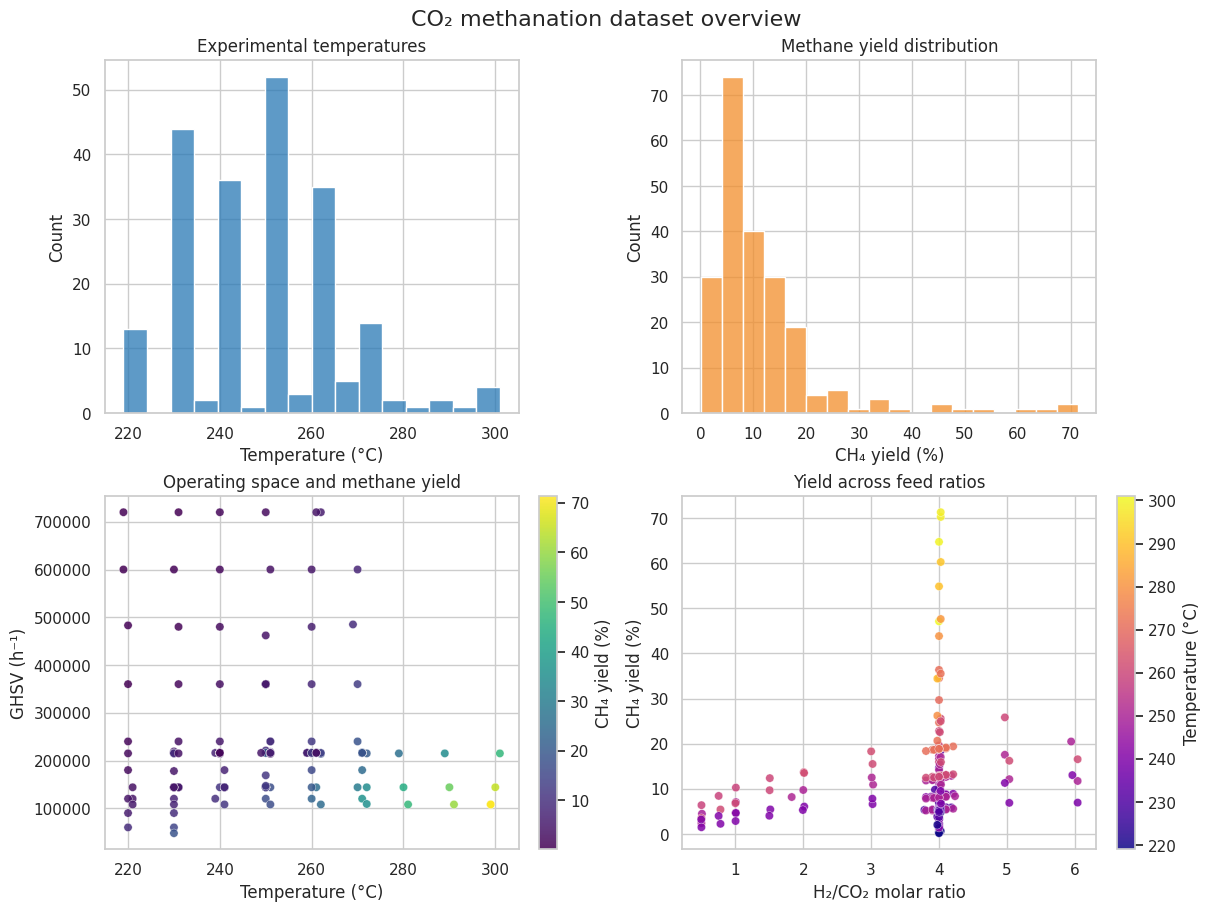

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)

sns.histplot(df, x='temperature_C', bins=16, ax=axes[0, 0], color='#2878B5')
axes[0, 0].set(title='Experimental temperatures', xlabel='Temperature (°C)')

sns.histplot(df, x='CH4_yield_pct', bins=18, ax=axes[0, 1], color='#F28E2B')
axes[0, 1].set(title='Methane yield distribution', xlabel='CH₄ yield (%)')

points = axes[1, 0].scatter(
    df['temperature_C'], df['GHSV_h-1'], c=df['CH4_yield_pct'],
    cmap='viridis', alpha=0.85, edgecolor='white', linewidth=0.3
)
axes[1, 0].set(
    title='Operating space and methane yield',
    xlabel='Temperature (°C)', ylabel='GHSV (h⁻¹)'
)
fig.colorbar(points, ax=axes[1, 0], label='CH₄ yield (%)')

ratio_points = axes[1, 1].scatter(
    df['H2_CO2_ratio'], df['CH4_yield_pct'], c=df['temperature_C'],
    cmap='plasma', alpha=0.85, edgecolor='white', linewidth=0.3
)
axes[1, 1].set(
    title='Yield across feed ratios',
    xlabel='H₂/CO₂ molar ratio', ylabel='CH₄ yield (%)'
)
fig.colorbar(ratio_points, ax=axes[1, 1], label='Temperature (°C)')

fig.suptitle('CO₂ methanation dataset overview', fontsize=16)
fig.savefig(FIGURE_DIR / 'eda_overview.png', dpi=180, bbox_inches='tight')
plt.show()

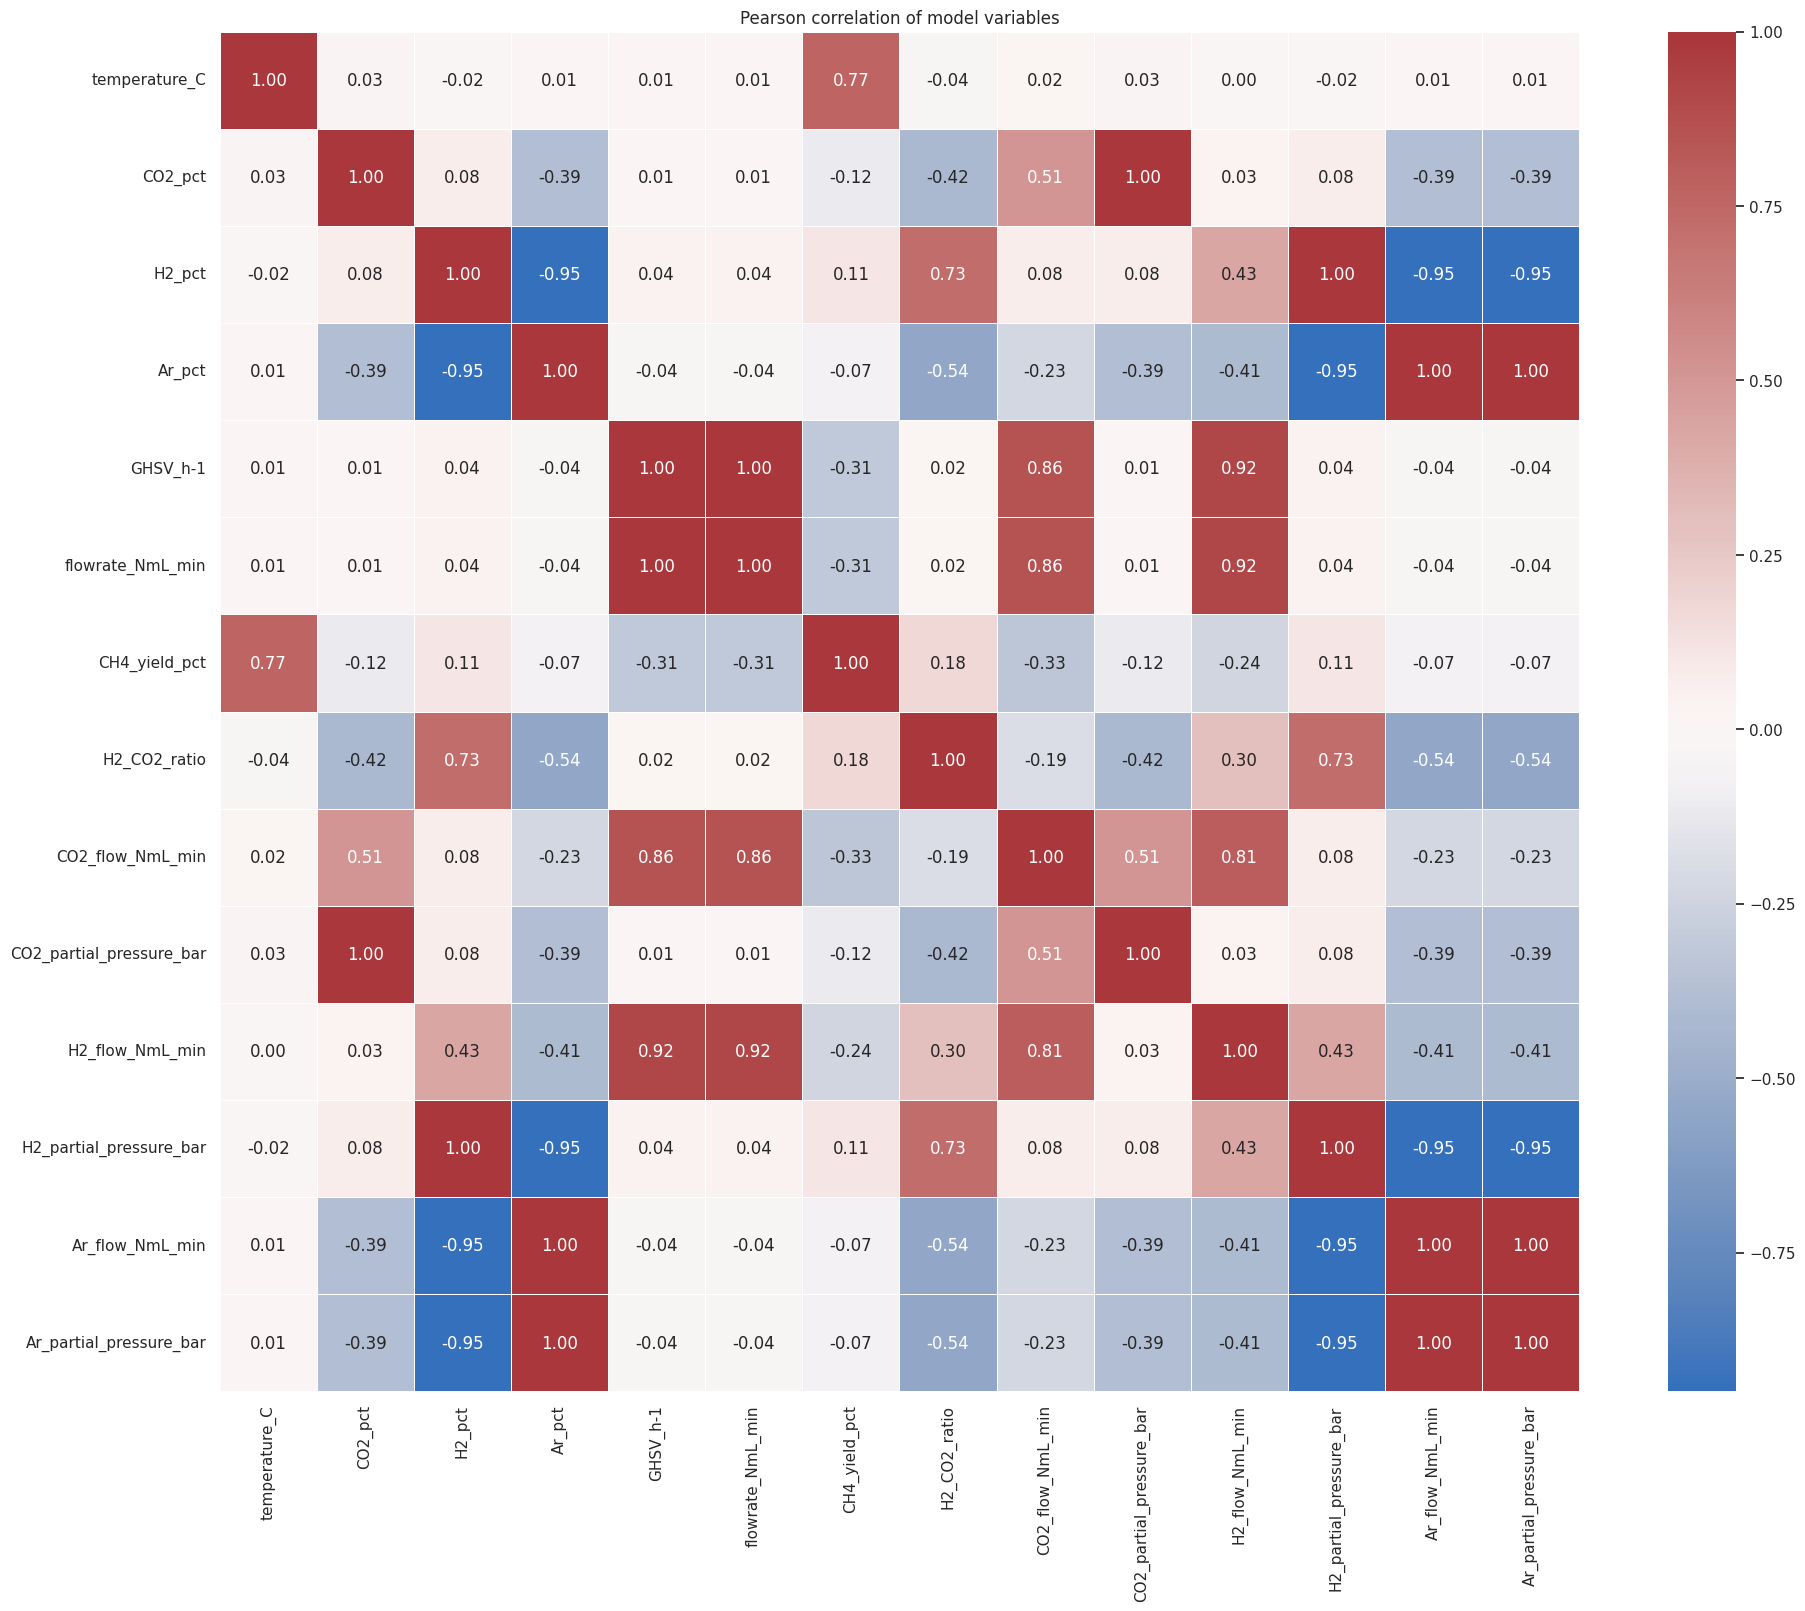

In [60]:
correlation = df[df.columns.drop(["test_id", "pressure_bar"])].corr()
fig, ax = plt.subplots(figsize=(20, 16), constrained_layout=True)
sns.heatmap(
    correlation, annot=True, fmt='.2f', cmap='vlag', center=0,
    square=True, linewidths=0.5, ax=ax
)
ax.set_title('Pearson correlation of model variables')
fig.savefig(FIGURE_DIR / 'correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

The three axes show temperature, GHSV, and H₂/CO₂ ratio. Point color adds the experimental methane yield without using another spatial dimension.

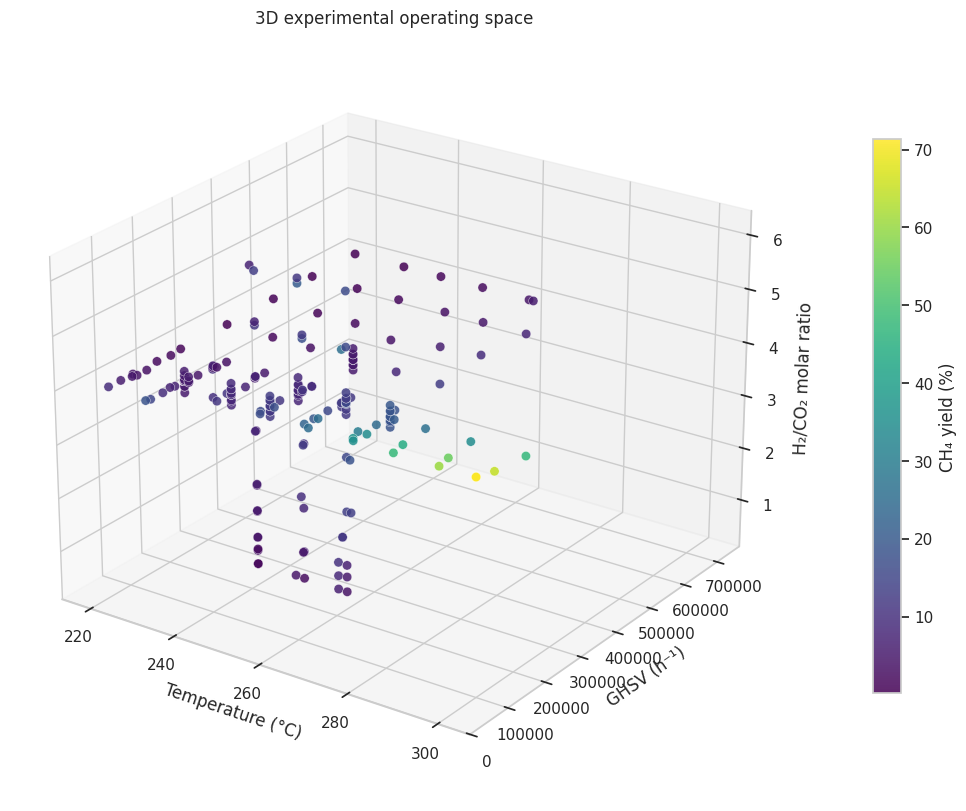

In [61]:
fig = plt.figure(figsize=(11, 8), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
points_3d = ax.scatter(
    df['temperature_C'],
    df['GHSV_h-1'],
    df['H2_CO2_ratio'],
    c=df['CH4_yield_pct'],
    cmap='viridis', s=45, alpha=0.85, edgecolor='white', linewidth=0.3
)
ax.set(
    title='3D experimental operating space',
    xlabel='Temperature (°C)',
    ylabel='GHSV (h⁻¹)',
    zlabel='H₂/CO₂ molar ratio'
)
ax.view_init(elev=24, azim=-55)
fig.colorbar(points_3d, ax=ax, shrink=0.72, pad=0.10, label='CH₄ yield (%)')
fig.savefig(FIGURE_DIR / 'operating_space_3d.png', dpi=180, bbox_inches='tight')
plt.show()